# 🧠 Neyron şəbəkələrinin əsasları — praktiki Jupyter Notebook

**Mövzular:** PyTorch & NN · Loss Functions · Softmax & Cross-Entropy · Optimizers  
**Tapşırığın son tarixi:** 22 noyabr 2026 · **Dil:** Azərbaycan dili

Bu notebook GitHub üçün hazırlanmış geniş [`neyron_sebekeleri_arasdirma.md`](./neyron_sebekeleri_arasdirma.md) sənədinin **praktiki davamıdır**. Bütün nümunələr internet tələb etmədən, yalnız süni yaradılmış verilənlərlə CPU-da işləyə bilər.

**Öyrənəcəyik:**
1. Tensor, `autograd`, `nn.Module`, `nn.Linear` və `forward()`;
2. MSE, BCEWithLogits, CrossEntropy;
3. Softmax, logit, sinif indeksləri, numerik sabitlik;
4. SGD, Adam, `zero_grad` / `backward` / `step`;
5. Tam 3 sinifli model, validation, qrafiklər, SGD–Adam müqayisəsi;
6. Kiçik özünü-yoxlama təcrübələri.

**Başlanğıc:** `python -m pip install torch matplotlib notebook` → `jupyter notebook` → `Kernel → Restart & Run All`.

> Sürətli yaddaş: **Model proqnoz verir → loss səhvi hesablayır → backward qradiyent verir → optimizer çəkiləri yeniləyir.**

## 0. Mühit yoxlaması

Ən azı `torch` və `matplotlib` lazımdır. `torch`-u rəsmi [quraşdırma səhifəsində](https://pytorch.org/get-started/locally/) mühitinizə uyğun qurun. Təkrarolunma üçün `manual_seed` təyin edirik; bütün platformalarda bit-bit eyni nəticə zəmanətli deyil.

In [1]:
import copy
import math
import tempfile
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("PyTorch versiyası:", torch.__version__)
print("CUDA mövcuddur:", torch.cuda.is_available())
print("Bu notebook üçün cihaz: CPU (portativ nümunələr)")

PyTorch versiyası: 2.10.0+cpu
CUDA mövcuddur: False
Bu notebook üçün cihaz: CPU (portativ nümunələr)


## 1. PyTorch & Neural Networks

### 1.1. Tensor nədir? Harada istifadə olunur?
Tensor 0D–ND ədədi verilənlər strukturudur. Məsələn, `[batch_size, features]` formasında obyekt xüsusiyyətləri saxlanır. `shape` və `dtype` səhvləri neyron şəbəkələrində çox rast gəlinir.

**Tensor olmasa** hesablama üçün başqa struktur (NumPy massivi, Python list-i və s.) lazımdır. PyTorch tensorları autograd və GPU imkanları ilə inteqrasiya yaradır.

In [2]:
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("Tensor:\n", x)
print("Shape:", tuple(x.shape), "dtype:", x.dtype, "device:", x.device)
print("Sətir ortalamaları:", x.mean(dim=1))
assert x.shape == (2, 2)

Tensor:
 tensor([[1., 2.],
        [3., 4.]])
Shape: (2, 2) dtype: torch.float32 device: cpu
Sətir ortalamaları: tensor([1.5000, 3.5000])


### 1.2. `autograd` — diferensiallama

$$f(x)=x^2+3x,\qquad f'(x)=2x+3$$

`x=2` üçün törəmə **7** olmalıdır. `backward()` qradiyent hesablayır, amma modeli **yeniləmir**. Əgər yeni hesablama öncəsi `.grad` təmizlənməsə, qradiyentlər toplanır.

In [3]:
a = torch.tensor(2.0, requires_grad=True)
loss_toy = a ** 2 + 3 * a
loss_toy.backward()
print("f(2)=", loss_toy.item(), "f'(2)=", a.grad.item())
assert a.grad.item() == 7.0

# Qradiyentlərin toplanmasını nümayiş etdiririk
a.grad.zero_()
(a ** 2).backward()  # törəmə 4
(a ** 2).backward()  # üzərinə daha 4 toplanır
print("İki backward sonrası .grad:", a.grad.item())
assert a.grad.item() == 8.0

f(2)= 10.0 f'(2)= 7.0
İki backward sonrası .grad: 8.0


### 1.3. `nn.Module`, `nn.Linear`, `forward()`

- **`nn.Module` nədir?** Parametrləri qeydiyyata alan, qatları birləşdirən model interfeysi.
- **`nn.Linear` nədir?** $Y=XW^T+b$ çevrilməsi.
- **`forward()` nədir?** Girişin çıxışa çevrilməsi qaydası.
- **Niyə `ReLU`?** Xətti qatlar arasına qeyri-xəttilik gətirir.
- **Olmasa?** Aktivasiya yoxdursa, ardıcıl xətti qatlar yenə xətti çevrilməyə bərabərdir.

`nn.Linear(4, 8)` üçün parametr sayı: `4*8 + 8 = 40`; `nn.Linear(8, 3)` üçün `8*3 + 3 = 27`. Cəmi **67**.

In [4]:
class KicikSebeke(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 3)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))  # xam logits

example_model = KicikSebeke()
example_input = torch.randn(5, 4)
example_logits = example_model(example_input)
num_params = sum(parameter.numel() for parameter in example_model.parameters())
print("Giriş:", tuple(example_input.shape), "Çıxış:", tuple(example_logits.shape))
print("Öyrənilən parametr sayı:", num_params)
assert example_logits.shape == (5, 3)
assert num_params == 67

Giriş: (5, 4) Çıxış: (5, 3)
Öyrənilən parametr sayı: 67


### 1.4. Qeyri-xəttilik niyə vacibdir?

İki xətti qatın kompozisiyası da xəttidir:

$$W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$$

Aşağıdakı kod bunu təsdiqləyir. Real qeyri-xətti nümunələr üçün gizli qatlarda ReLU kimi aktivasiya istifadə edilir.

In [5]:
torch.manual_seed(7)
linear1 = nn.Linear(2, 4)
linear2 = nn.Linear(4, 3)
example_x = torch.randn(6, 2)

stacked = linear2(linear1(example_x))
combined_W = linear2.weight @ linear1.weight
combined_b = linear2.weight @ linear1.bias + linear2.bias
collapsed = F.linear(example_x, combined_W, combined_b)
print("İki xətti qat = tək xətti çevrilmə:", torch.allclose(stacked, collapsed, atol=1e-6))
assert torch.allclose(stacked, collapsed, atol=1e-6)

İki xətti qat = tək xətti çevrilmə: True


## 2. Loss Functions

**Loss nədir?** Model proqnozunun həqiqi hədəfdən nə qədər fərqləndiyini ölçən optimallaşdırma funksiyasıdır.

| Vəzifə | Loss | Gücü | Məhdudiyyət |
|---|---|---|---|
| Reqressiya | MSE | Böyük xətalara yüksək cəza | Outlier-lərə həssasdır |
| Reqressiya | MAE / SmoothL1 | Xüsusən iri xətalara daha dözümlü yanaşma | Seçim və miqyas problemə bağlıdır |
| Binary / multi-label | BCEWithLogitsLoss | Sigmoid və BCE-nin sabit birləşməsi | Forma və balans məsələləri |
| Multiclass | CrossEntropyLoss | Logitlərlə birbaşa işləyir | Yanlış etiketlər və balanssızlıq |

**Loss olmasa** standart gradient əsaslı təlim üçün səhvi hədəfləyən obyektiv olmaz.

In [6]:
# REGRESSION: MSE, MAE, SmoothL1
pred = torch.tensor([3.0, 5.0, 4.0])
truth = torch.tensor([2.0, 4.0, 6.0])
mse = nn.MSELoss()(pred, truth)
mae = nn.L1Loss()(pred, truth)
smooth_l1 = nn.SmoothL1Loss()(pred, truth)
print(f"MSE={mse.item():.4f} | MAE={mae.item():.4f} | SmoothL1={smooth_l1.item():.4f}")
assert math.isclose(mse.item(), 2.0)

MSE=2.0000 | MAE=1.3333 | SmoothL1=0.8333


### 2.1. İkili təsnifat — BCEWithLogitsLoss

`BCEWithLogitsLoss` **xam logit** qəbul edir. Sonra ehtimal lazım olarsa `sigmoid` tətbiq edilir.

- **Üstünlük:** `Sigmoid`+`BCELoss`-u birləşdirərək daha yaxşı ədədi sabitlik təmin edir.
- **Mənfi tərəf:** Etiket və model çıxışı eyni ölçüdə olmalıdır; balanssız datasetdə ayrıca strategiya lazım gələ bilər.
- **İstifadə:** spam, təhlükə var/yox, birdən çox müstəqil etiket.

In [7]:
binary_logits = torch.tensor([[1.2], [-0.5], [0.7]])
binary_labels = torch.tensor([[1.0], [0.0], [1.0]])
bce = nn.BCEWithLogitsLoss()(binary_logits, binary_labels)
print("Binary loss:", round(bce.item(), 4))
print("Sigmoid ehtimalları:", torch.sigmoid(binary_logits).squeeze().tolist())
assert bce.ndim == 0

Binary loss: 0.3802
Sigmoid ehtimalları: [0.7685248255729675, 0.3775406777858734, 0.6681877374649048]


### 2.2. Çoxsinifli təsnifat — CrossEntropyLoss

`CrossEntropyLoss(logits, labels)` istifadə etdikdə:

- `logits` forması: **`(N, C)`**;
- sinif indeksli `labels` forması: **`(N,)`**, tipi **`torch.long`**;
- son çıxışa **Softmax əlavə edilmir**.

`CrossEntropyLoss` bəzi hallarda eyni ölçülü yumşaq sinif paylanmalarını da hədəf kimi qəbul edə bilir. Burada standart indeksli variantı öyrənirik.

In [8]:
ce_logits = torch.tensor([[2.0, 1.0, 0.1], [0.2, 0.3, 1.9]])
ce_targets = torch.tensor([0, 2], dtype=torch.long)
criterion = nn.CrossEntropyLoss()
ce_result = criterion(ce_logits, ce_targets)
print("Logits forması:", tuple(ce_logits.shape), "Labels forması:", tuple(ce_targets.shape))
print("CrossEntropyLoss:", round(ce_result.item(), 5))
assert ce_logits.shape == (2, 3) and ce_targets.shape == (2,)

Logits forması: (2, 3) Labels forması: (2,)
CrossEntropyLoss: 0.37121


## 3. Softmax & Cross Entropy

**Softmax nədir?** Logitləri hər sətir üzrə cəmi 1 olan sinif ehtimal paylanmasına çevirən funksiya:

$$p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

**Niyə?** Sinif skorlarını müqayisəli ehtimallar kimi oxumaq üçün. **Olmasa?** `argmax(logits)` ilə sinif seçmək olar, amma ehtimal paylanması alınmaz. **Mənfi tərəf:** yüksək payın kalibrlənmiş əminlik olmasına zəmanət yoxdur; multi-label üçün uyğun deyil.

In [9]:
sample_logits = torch.tensor([[2.0, 1.0, 0.1], [0.1, 0.2, 2.0]])
probabilities = torch.softmax(sample_logits, dim=1)
print("Softmax ehtimalları:\n", probabilities)
print("Sətir cəmləri:", probabilities.sum(dim=1))
print("Proqnoz siniflər:", probabilities.argmax(dim=1).tolist())
assert torch.allclose(probabilities.sum(dim=1), torch.ones(2), atol=1e-6)

Softmax ehtimalları:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.1138, 0.1257, 0.7605]])
Sətir cəmləri: tensor([1.0000, 1.0000])
Proqnoz siniflər: [0, 2]


### 3.1. CE necə hesablanır?

Bir nümunədə hədəf sinif `k` olduqda:

$$\mathrm{CE}=-\log(\operatorname{Softmax}(z)_k)$$

**Doğru:** `nn.CrossEntropyLoss()(logits, y)`  
**Yanlış:** `nn.CrossEntropyLoss()(torch.softmax(logits, dim=1), y)`

İkinci variant icra olunsa da, düzgün obyektiv funksiyası **deyil**. Təlim üçün Softmax-ı iki dəfə tətbiq etməyin.

In [10]:
one_logits = torch.tensor([[2.0, 1.0, 0.1]])
one_target = torch.tensor([0])
ce_builtin = nn.CrossEntropyLoss()(one_logits, one_target)
ce_manual = -torch.log_softmax(one_logits, dim=1)[0, one_target[0]]
wrong_double_softmax = nn.CrossEntropyLoss()(torch.softmax(one_logits, dim=1), one_target)
print(f"Düzgün daxili CE: {ce_builtin.item():.6f}")
print(f"Əl ilə log_softmax: {ce_manual.item():.6f}")
print(f"YANLIŞ ikiqat Softmax: {wrong_double_softmax.item():.6f}")
assert torch.allclose(ce_builtin, ce_manual, atol=1e-7)
assert not torch.allclose(ce_builtin, wrong_double_softmax)

Düzgün daxili CE: 0.417030
Əl ilə log_softmax: 0.417030
YANLIŞ ikiqat Softmax: 0.802121


### 3.2. Numerical stability — niyə `torch.softmax` istifadə olunur?

Böyük logitlərdə birbaşa `exp` hesabı overflow verə bilər. `torch.softmax` daha sabit hesablamadan istifadə edir.

In [11]:
huge_logits = torch.tensor([[1000.0, 1001.0, 999.0]])
naive_softmax = torch.exp(huge_logits) / torch.exp(huge_logits).sum(dim=1, keepdim=True)
stable_softmax = torch.softmax(huge_logits, dim=1)
print("Naive (potensial nan):", naive_softmax)
print("Stabil Softmax:", stable_softmax)
assert torch.isfinite(stable_softmax).all()

Naive (potensial nan): tensor([[nan, nan, nan]])
Stabil Softmax: tensor([[0.2447, 0.6652, 0.0900]])


### 3.3. Softmax və Sigmoid müqayisəsi

- **Multiclass:** Bir sinif doğrudur → Softmax + `CrossEntropyLoss` (təlimdə logits).
- **Multi-label:** Eyni anda bir neçə sinif doğru ola bilər → hər çıxışa Sigmoid + `BCEWithLogitsLoss` (təlimdə logits).

Bu fərqi şəkillərdə bir neçə obyektin olması və futbol nəticələrində yalnız bir yekun nəticənin olması üzərində düşünün.

In [12]:
multi_label_logits = torch.tensor([[2.0, 1.5, -1.0]])
independent_probs = torch.sigmoid(multi_label_logits)
exclusive_probs = torch.softmax(multi_label_logits, dim=1)
print("Multi-label, müstəqil Sigmoid:", independent_probs.tolist())
print("Multiclass, Softmax:", exclusive_probs.tolist())
print("Sigmoid cəmi (1 olmalı deyil):", independent_probs.sum().item())
print("Softmax cəmi:", exclusive_probs.sum().item())

Multi-label, müstəqil Sigmoid: [[0.8807970285415649, 0.8175744414329529, 0.2689414322376251]]
Multiclass, Softmax: [[0.6037489175796509, 0.3661922216415405, 0.030058886855840683]]
Sigmoid cəmi (1 olmalı deyil): 1.9673128128051758
Softmax cəmi: 1.0


## 4. Optimizers — SGD, Adam, Learning Rate

Optimizer **parametrləri yeniləyir**, `backward()` isə yalnız qradiyent hesablayır.

Gradient descent:

$$\theta_{new}=\theta-\eta \nabla_\theta L$$

**SGD** sadə addım və istəyə görə momentum; **Adam** adaptiv momentlərdən istifadə edir. Heç biri həmişə qalib deyil.

- **LR çox kiçikdirsə:** öyrənmə yavaşdır.
- **LR çox böyükdürsə:** loss qeyri-sabit ola bilər.
- **Optimizer olmasa:** `backward()` çəkiləri avtomatik dəyişməz.

In [13]:
w = torch.tensor(0.0, requires_grad=True)
sgd_scalar = torch.optim.SGD([w], lr=0.1)
for step in range(5):
    sgd_scalar.zero_grad()
    one_dim_loss = (w - 3) ** 2
    one_dim_loss.backward()
    sgd_scalar.step()
    print(f"Addım {step+1}: w={w.item():.4f}, əvvəlki loss={one_dim_loss.item():.4f}")
assert w.item() > 0.0

Addım 1: w=0.6000, əvvəlki loss=9.0000
Addım 2: w=1.0800, əvvəlki loss=5.7600
Addım 3: w=1.4640, əvvəlki loss=3.6864
Addım 4: w=1.7712, əvvəlki loss=2.3593
Addım 5: w=2.0170, əvvəlki loss=1.5099


### 4.1. `backward()`-un özü parametri dəyişmir

Aşağıdakı kodda əvvəl qradiyent hesablanır, amma `step()` çağırılana qədər çəki olduğu kimi qalır.

In [14]:
weight_demo = torch.tensor(0.0, requires_grad=True)
opt_demo = torch.optim.SGD([weight_demo], lr=0.1)
opt_demo.zero_grad()
loss_demo = (weight_demo - 3) ** 2
loss_demo.backward()
print("Backward-dan sonra çəki:", weight_demo.item(), "gradient:", weight_demo.grad.item())
assert weight_demo.item() == 0.0
opt_demo.step()
print("Optimizer.step()-dən sonra çəki:", weight_demo.item())
assert math.isclose(weight_demo.item(), 0.6, abs_tol=1e-6)

Backward-dan sonra çəki: 0.0 gradient: -6.0
Optimizer.step()-dən sonra çəki: 0.6000000238418579


## 5. Tam model: 3 sinifli synthetic dataset

Real dataset endirmirik. 2 ölçülü məkanda üç müxtəlif mərkəz ətrafında nöqtələr yaradırıq. Bu, **təlim axınını öyrətmək** üçündür, real məlumatların mürəkkəbliyini təmsil etmir.

**Train** — öyrənmə; **validation** — ayrıca yoxlama. Vaxt sıralı real məsələlərdə təsadüfi split əvəzinə zaman üzrə ayrılma lazım ola bilər.

In [15]:
torch.manual_seed(42)
centers = torch.tensor([[-2.0, -2.0], [2.0, -2.0], [0.0, 2.0]])
X = torch.cat([center + 0.7 * torch.randn(240, 2) for center in centers])
y = torch.cat([torch.full((240,), i, dtype=torch.long) for i in range(3)])
perm = torch.randperm(len(X))
train_ids, valid_ids = perm[:576], perm[576:]
X_train, y_train = X[train_ids], y[train_ids]
X_valid, y_valid = X[valid_ids], y[valid_ids]

print("Train:", tuple(X_train.shape), tuple(y_train.shape))
print("Validation:", tuple(X_valid.shape), tuple(y_valid.shape))
assert len(X_train) == 576 and len(X_valid) == 144

Train: (576, 2) (576,)
Validation: (144, 2) (144,)


### 5.1. Verilənləri vizuallaşdıraq

Siniflər bir-birindən kifayət qədər ayrılır. Qrafikdə hər rəng fərqli sinifdir.

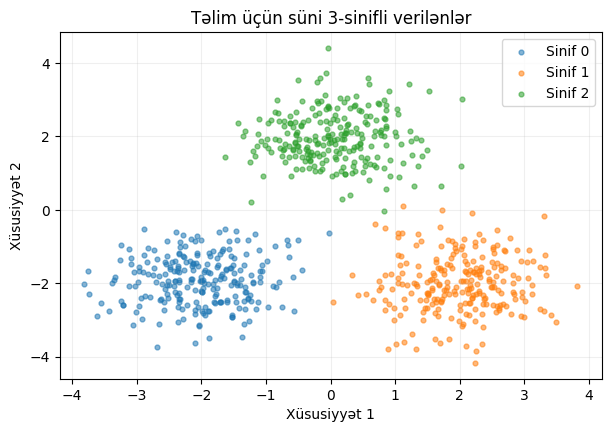

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for cls in range(3):
    mask = (y == cls)
    ax.scatter(X[mask, 0].numpy(), X[mask, 1].numpy(), s=12, alpha=0.55, label=f"Sinif {cls}")
ax.set(title="Təlim üçün süni 3-sinifli verilənlər", xlabel="Xüsusiyyət 1", ylabel="Xüsusiyyət 2")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### 5.2. Model qururuq və Adam ilə öyrədirik

Son qat **3 xam logit** verir. **Softmax təlimdə yoxdur.**

Təlim addımları: `zero_grad()` → `forward` → `CrossEntropyLoss` → `backward()` → `step()`.

In [17]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 3),
        )

    def forward(self, x):
        return self.net(x)  # xam logitlər

torch.manual_seed(123)
model = Classifier()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(42))

history_train, history_valid, history_acc = [], [], []
for epoch in range(40):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(xb)

    train_loss = running_loss / len(X_train)
    model.eval()
    with torch.no_grad():
        logits_val = model(X_valid)
        val_loss = criterion(logits_val, y_valid).item()
        val_acc = (logits_val.argmax(dim=1) == y_valid).float().mean().item()
    history_train.append(train_loss)
    history_valid.append(val_loss)
    history_acc.append(val_acc)
    if epoch in (0, 9, 19, 39):
        print(f"Epoch {epoch+1:2d}: train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.1%}")

assert math.isfinite(history_train[-1])
assert history_acc[-1] > 0.85, "Bu asan synthetic datasətdə yüksək accuracy gözlənir"

Epoch  1: train_loss=0.2548 | val_loss=0.0135 | val_acc=100.0%
Epoch 10: train_loss=0.0050 | val_loss=0.0004 | val_acc=100.0%
Epoch 20: train_loss=0.0034 | val_loss=0.0002 | val_acc=100.0%


Epoch 40: train_loss=0.0026 | val_loss=0.0001 | val_acc=100.0%


### 5.3. Təlimin qrafiki

Train və validation loss arasında ciddi fərq açılarsa overfitting ehtimalını araşdırın; təkcə aşağı train loss kifayət etmir.

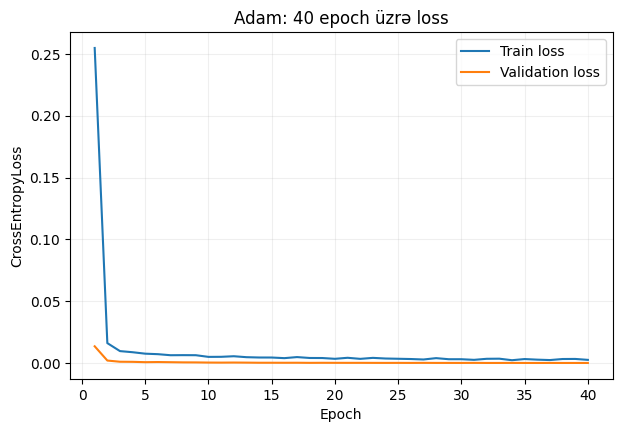

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, 41), history_train, label="Train loss")
ax.plot(range(1, 41), history_valid, label="Validation loss")
ax.set(title="Adam: 40 epoch üzrə loss", xlabel="Epoch", ylabel="CrossEntropyLoss")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

### 5.4. Yeni nümunəyə proqnoz və Softmax

`argmax(logits)` ilə `argmax(softmax(logits))` eyni sinfi verir. **Lakin ehtimal mütləq etibarlı əminlik deyil.**

In [19]:
new_samples = torch.tensor([[0.0, 2.5], [-2.5, -2.0], [2.6, -1.7]])
model.eval()
with torch.no_grad():
    prediction_logits = model(new_samples)
    prediction_probabilities = torch.softmax(prediction_logits, dim=1)
    predicted_classes = prediction_probabilities.argmax(dim=1)

for i in range(len(new_samples)):
    print(f"Nümunə {i+1}: sinif={predicted_classes[i].item()}, "
          f"ehtimallar={[round(v, 4) for v in prediction_probabilities[i].tolist()]}")
assert torch.equal(prediction_logits.argmax(dim=1), predicted_classes)

Nümunə 1: sinif=2, ehtimallar=[0.0, 0.0, 1.0]
Nümunə 2: sinif=0, ehtimallar=[1.0, 0.0, 0.0]
Nümunə 3: sinif=1, ehtimallar=[0.0, 1.0, 0.0]


### 5.5. Modelin saxlanması və yüklənməsi

Praktikaya görə yalnız `state_dict` saxlayırıq. Əgər modeli real istifadə üçün saxlayırsınızsa, onun arxitekturasını və girişlərin emalını da versiyalaşdırın.

In [20]:
with tempfile.TemporaryDirectory() as tmp:
    file_path = Path(tmp) / "my_classifier.pt"
    torch.save(model.state_dict(), file_path)
    restored = Classifier()
    restored.load_state_dict(torch.load(file_path, map_location="cpu", weights_only=True))
    restored.eval()
    with torch.no_grad():
        assert torch.allclose(restored(new_samples), model(new_samples), atol=1e-6)
    print("state_dict uğurla saxlanıldı və bərpa olundu.")

state_dict uğurla saxlanıldı və bərpa olundu.


## 6. SGD və Adam müqayisəsi

**Ədalətli müqayisə üçün:** eyni başlanğıc çəkiləri, eyni verilən bölgüsü və batch sırası, eyni epoch sayı istifadə edilir. Buradakı learning rate-lər **nümunə** üçündür; hər optimizer üçün optimal dəyər olmaya bilər.

Bu qrafikdən **“Adam həmişə yaxşıdır”** nəticəsi çıxarmayın — fərqli model, dataset və tuning başqa nəticə verə bilər.

SGD: son train loss=0.0046, val accuracy=100.0%
Adam: son train loss=0.0047, val accuracy=100.0%


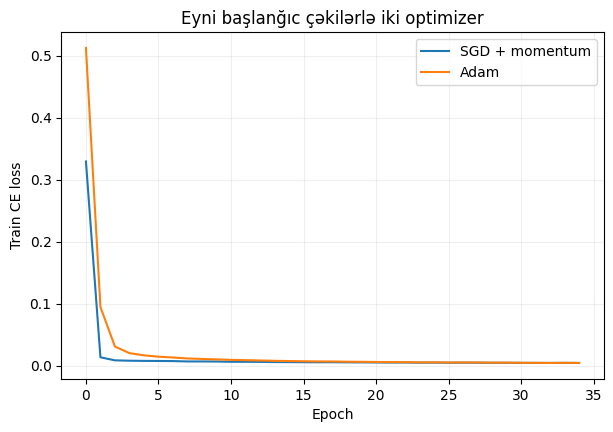

In [21]:
torch.manual_seed(1234)
initial_model = Classifier()
initial_state = copy.deepcopy(initial_model.state_dict())


def train_with_optimizer(optimizer_name, epochs=35):
    current_model = Classifier()
    current_model.load_state_dict(copy.deepcopy(initial_state))
    if optimizer_name == "SGD":
        current_optimizer = torch.optim.SGD(current_model.parameters(), lr=0.05, momentum=0.9)
    elif optimizer_name == "Adam":
        current_optimizer = torch.optim.Adam(current_model.parameters(), lr=0.01)
    else:
        raise ValueError("Optimizer yalnız SGD və ya Adam ola bilər")

    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(2026))
    losses, accuracies = [], []
    for epoch in range(epochs):
        current_model.train()
        running = 0.0
        for xb, yb in loader:
            current_optimizer.zero_grad()
            output = current_model(xb)
            batch_loss = criterion(output, yb)
            batch_loss.backward()
            current_optimizer.step()
            running += batch_loss.item() * len(xb)
        current_model.eval()
        with torch.no_grad():
            val_logits = current_model(X_valid)
            val_acc = (val_logits.argmax(1) == y_valid).float().mean().item()
        losses.append(running / len(X_train))
        accuracies.append(val_acc)
    return losses, accuracies

sgd_losses, sgd_acc = train_with_optimizer("SGD")
adam_losses, adam_acc = train_with_optimizer("Adam")
print(f"SGD: son train loss={sgd_losses[-1]:.4f}, val accuracy={sgd_acc[-1]:.1%}")
print(f"Adam: son train loss={adam_losses[-1]:.4f}, val accuracy={adam_acc[-1]:.1%}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sgd_losses, label="SGD + momentum")
ax.plot(adam_losses, label="Adam")
ax.set(title="Eyni başlanğıc çəkilərlə iki optimizer", xlabel="Epoch", ylabel="Train CE loss")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 7. Düşün və sına — ev tapşırığı

Aşağıdakı tapşırıqları özünüz yerinə yetirin. Hər tapşırıq üçün **nə baş verdi və niyə?** suallarına cavab yazın.

1. `nn.Linear(5,10)` üçün parametr sayını hesablayın. **İpucu:** $5\times 10+10$.
2. `x=3` üçün `x² + 2x` funksiyasının törəməsini autograd ilə göstərin. **Gözlənən:** 8.
3. `[1,2,3]` logitlərinin Softmax ehtimal cəminin 1 olduğunu yoxlayın.
4. `CrossEntropyLoss` ilə `-log_softmax` nəticələrinin bərabərliyini təsdiqləyin.
5. Modelin təlimindən **`optimizer.step()`** çıxarsanız, nə baş verər?
6. `Adam` learning rate dəyərini `0.02`-dən `0.00001`-ə endirin və təlim sürətini müqayisə edin.
7. `ReLU` qatını çıxarın və mürəkkəb verilənlərdə bunun təsirini müzakirə edin.
8. Multi-label problem üçün niyə Softmax əvəzinə Sigmoid/BCEWithLogits istifadə olunur?
9. Train loss azalarkən validation loss artsa hansı problem ehtimal olunur?
10. `model.eval()` ilə `torch.no_grad()` fərqini izah edin.

### Özünü yoxlama üçün avtomatik testlər

Aşağıdakı blok yuxarıdakı nümunələrin əsas riyazi davranışlarını yoxlayır.

In [22]:
# Avtomatik yoxlamalar
assert sum(p.numel() for p in nn.Linear(5, 10).parameters()) == 60

x_quiz = torch.tensor(3.0, requires_grad=True)
(x_quiz**2 + 2*x_quiz).backward()
assert x_quiz.grad.item() == 8.0

quiz_probs = torch.softmax(torch.tensor([[1.0, 2.0, 3.0]]), dim=1)
assert torch.allclose(quiz_probs.sum(dim=1), torch.ones(1))

quiz_logits = torch.tensor([[0.2, 2.5, -1.0]])
quiz_y = torch.tensor([1])
ce_a = nn.CrossEntropyLoss()(quiz_logits, quiz_y)
ce_b = -torch.log_softmax(quiz_logits, dim=1)[0, 1]
assert torch.allclose(ce_a, ce_b)

print("✅ 4 əsas yoxlama uğurla keçdi. Qalan sualları izah etməklə tamamlayın.")

✅ 4 əsas yoxlama uğurla keçdi. Qalan sualları izah etməklə tamamlayın.


## 8. Nəticə: hər bir anlayışın rolu

| Anlayış | Nədir? | Nə üçün lazımdır? | Olmasa? |
|---|---|---|---|
| `nn.Module` | Model quruluşu | Qat və parametrlərin idarəsi | Əllə daha çox iş və ya başqa abstraksiya |
| `nn.Linear` | $XW^T+b$ | Öyrənilən xətti transformasiya | Başqa qat / parametr strukturu tələb oluna bilər |
| `forward()` | Girişdən çıxışa hesablamalar | Proqnoz yaratmaq | Modelin çıxışı müəyyən olmaz |
| `Loss` | Səhv ölçüsü | Təlimin məqsədi | Optimallaşdırma məqsədi olmaz |
| `Softmax` | Logit→sinif ehtimalları | Multiclass ehtimalı təqdim etmək | Sinfi argmax ilə seçmək olar |
| `CrossEntropyLoss` | Təsnifat itkisi | Doğru sinfə pay artırmaq | Başqa uyğun loss lazımdır |
| `backward()` | Qradiyent hesablanması | Öyrənmə istiqaməti | Yeni qradiyent yaranmaz |
| `SGD/Adam` | Parametr yeniləyən optimizer | Çəkiləri yaxşılaşdırmaq | Model avtomatik öyrənməz |

**Yadda saxlayın:** `CrossEntropyLoss`-a həmişə bu nümunələrdə **xam logit**, sinif indeksli hədəfə isə `torch.long` verilir. Təlimdə `zero_grad → forward → loss → backward → step` ardıcıllığını qoruyun.

**Rəsmi mənbələr:** [PyTorch Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html) · [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) · [Softmax](https://docs.pytorch.org/docs/stable/generated/torch.nn.Softmax.html) · [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) · [Optimizers](https://docs.pytorch.org/docs/stable/optim.html).

📖 **Daha geniş nəzəri hissə:** [`neyron_sebekeleri_arasdirma.md`](./neyron_sebekeleri_arasdirma.md).